# 1. Environment

In [1]:
!pip -q install -U transformers datasets accelerate safetensors matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 16.4 MB/s eta 0:00:00


In [2]:
import torch
import transformers
import datasets
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)

    print("GPU:", gpu.name)
    print(f"VRAM: {gpu.total_memory / 1024**3:.2f} GB")
    print("BF16 supported:", torch.cuda.is_bf16_supported())

Python: 3.12.13
PyTorch: 2.11.0+cu128
Transformers: 5.15.0
Datasets: 5.0.1

CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB
BF16 supported: True


#2. Loading the baseline model

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

MODEL_ID = "Qwen/Qwen2.5-1.5B"

# Explicitly use FP16 for our baseline
DTYPE = torch.float16

print("Loading:", MODEL_ID)
print("Using dtype:", DTYPE)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    device_map={"": 0},
    low_cpu_mem_usage=True,
    attn_implementation="sdpa",
)

model.eval()

print("Model loaded.")
print("Model dtype:", model.dtype)
print("Model device:", model.device)

Loading: Qwen/Qwen2.5-1.5B
Using dtype: torch.float16


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Model loaded.
Model dtype: torch.float16
Model device: cuda:0


#3. Model configuration

In [4]:
config = model.config

num_layers = config.num_hidden_layers
num_attention_heads = config.num_attention_heads
num_kv_heads = getattr(
    config,
    "num_key_value_heads",
    num_attention_heads
)

hidden_size = config.hidden_size
head_dim = getattr(
    config,
    "head_dim",
    hidden_size // num_attention_heads
)

num_params = sum(p.numel() for p in model.parameters())

print("Number of parameters:", f"{num_params:,}")
print("Number of layers:", num_layers)
print("Hidden size:", hidden_size)
print("Attention heads:", num_attention_heads)
print("KV heads:", num_kv_heads)
print("Head dimension:", head_dim)
print("Model dtype:", model.dtype)

allocated = torch.cuda.memory_allocated() / 1024**3
reserved = torch.cuda.memory_reserved() / 1024**3

print(f"\nGPU memory allocated: {allocated:.3f} GiB")
print(f"GPU memory reserved:  {reserved:.3f} GiB")

Number of parameters: 1,543,714,304
Number of layers: 28
Hidden size: 1536
Attention heads: 12
KV heads: 2
Head dimension: 128
Model dtype: torch.float16

GPU memory allocated: 2.875 GiB
GPU memory reserved:  2.930 GiB


#4. Create and inspect the first KV cache

In [5]:
# Create an input of exactly 256 tokens

text = (
    "The key value cache stores intermediate attention states "
    "so that autoregressive language models can reuse previous "
    "keys and values instead of recomputing them at every decoding step. "
) * 100

input_ids = tokenizer(
    text,
    return_tensors="pt",
    add_special_tokens=False
).input_ids[:, :256]

input_ids = input_ids.to(model.device)

print("Input shape:", tuple(input_ids.shape))


# Run one forward pass and ask the model to create the KV cache
with torch.inference_mode():
    outputs = model(
        input_ids=input_ids,
        use_cache=True
    )

cache = outputs.past_key_values

print("Cache type:", type(cache))
print("Number of cache layers:", len(cache.layers))


# Inspect a few layers
for i in [0, 1, len(cache.layers) - 1]:
    key = cache.layers[i].keys
    value = cache.layers[i].values

    print(f"\nLayer {i}")
    print("K shape:", tuple(key.shape))
    print("V shape:", tuple(value.shape))
    print("K dtype:", key.dtype)
    print("V dtype:", value.dtype)
    print("K device:", key.device)
    print("V device:", value.device)

Input shape: (1, 256)
Cache type: <class 'transformers.cache_utils.DynamicCache'>
Number of cache layers: 28

Layer 0
K shape: (1, 2, 256, 128)
V shape: (1, 2, 256, 128)
K dtype: torch.float16
V dtype: torch.float16
K device: cuda:0
V device: cuda:0

Layer 1
K shape: (1, 2, 256, 128)
V shape: (1, 2, 256, 128)
K dtype: torch.float16
V dtype: torch.float16
K device: cuda:0
V device: cuda:0

Layer 27
K shape: (1, 2, 256, 128)
V shape: (1, 2, 256, 128)
K dtype: torch.float16
V dtype: torch.float16
K device: cuda:0
V device: cuda:0


### KV Cache Shape

For each transformer layer, the Key and Value cache tensors have the shape:

$$[B, H_{\text{KV}}, S, D_h]$$

where:

* **$B$** = batch size — number of sequences processed together.
* **$H_{\text{KV}}$** = number of Key/Value heads.
* **$S$** = sequence length — number of cached tokens.
* **$D_h$** = dimension of each attention head.

For **Qwen2.5-1.5B**, the observed shape is:

$$[1, 2, 256, 128]$$

meaning one sequence, 2 KV heads, 256 cached tokens, and 128 values per head. The model has 28 layers, and every layer stores both a Key tensor and a Value tensor.

Therefore, KV-cache memory grows linearly with the sequence length.

#5. Measure KV-cache memory

The formula we're testing is:

$$M_{\text{KV}} = 2 L B H_{\text{KV}} S D_h E$$

where $E$ is bytes per element and the initial $2$ represents $K + V$.

In [6]:
# Calculate actual KV-cache memory directly from the tensors

actual_cache_bytes = 0

for layer in cache.layers:
    key = layer.keys
    value = layer.values

    actual_cache_bytes += key.numel() * key.element_size()
    actual_cache_bytes += value.numel() * value.element_size()


# Theoretical calculation

batch_size = input_ids.shape[0]
seq_len = input_ids.shape[1]

# FP16 = 2 bytes per element
bytes_per_element = cache.layers[0].keys.element_size()

theoretical_cache_bytes = (
    2                       # Key + Value
    * num_layers
    * batch_size
    * num_kv_heads
    * seq_len
    * head_dim
    * bytes_per_element
)


# Convert to MiB
actual_cache_mib = actual_cache_bytes / (1024 ** 2)
theoretical_cache_mib = theoretical_cache_bytes / (1024 ** 2)

print(f"Sequence length:          {seq_len}")
print(f"Bytes per element:        {bytes_per_element}")
print(f"Actual KV cache:          {actual_cache_mib:.4f} MiB")
print(f"Theoretical KV cache:     {theoretical_cache_mib:.4f} MiB")
print(f"Difference:               {abs(actual_cache_bytes - theoretical_cache_bytes)} bytes")

# Useful additional number
bytes_per_token = actual_cache_bytes / seq_len

print(f"KV cache per token:       {bytes_per_token / 1024:.2f} KiB")

Sequence length:          256
Bytes per element:        2
Actual KV cache:          7.0000 MiB
Theoretical KV cache:     7.0000 MiB
Difference:               0 bytes
KV cache per token:       28.00 KiB


The measured KV-cache memory exactly matches the theoretical formula. For Qwen2.5-1.5B in FP16, a sequence of 256 tokens requires 7 MiB of KV-cache memory, corresponding to 28 KiB per cached token. Therefore, KV-cache memory grows linearly with sequence length.

#6. KV-cache memory vs. sequence length

In [7]:
import pandas as pd

sequence_lengths = [
    256,
    512,
    1024,
    2048,
    4096,
    8192,
    16384,
    32768
]

rows = []

for seq_len in sequence_lengths:
    cache_bytes = (
        2
        * num_layers
        * 1                  # batch size
        * num_kv_heads
        * seq_len
        * head_dim
        * bytes_per_element
    )

    rows.append({
        "Sequence Length": seq_len,
        "KV Cache (MiB)": cache_bytes / (1024 ** 2),
        "KV Cache (GiB)": cache_bytes / (1024 ** 3)
    })

memory_df = pd.DataFrame(rows)

display(memory_df)

,Sequence Length,KV Cache (MiB),KV Cache (GiB)
0,256,7.0,0.006836
1,512,14.0,0.013672
2,1024,28.0,0.027344
3,2048,56.0,0.054688
4,4096,112.0,0.109375
5,8192,224.0,0.218750
6,16384,448.0,0.437500
7,32768,896.0,0.875000


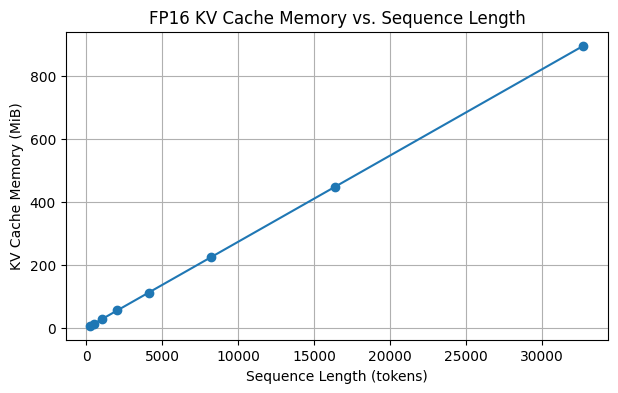

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    memory_df["Sequence Length"],
    memory_df["KV Cache (MiB)"],
    marker="o"
)

plt.xlabel("Sequence Length (tokens)")
plt.ylabel("KV Cache Memory (MiB)")
plt.title("FP16 KV Cache Memory vs. Sequence Length")
plt.grid(True)

plt.show()

###KV Cache Memory Scaling

For Qwen2.5-1.5B in FP16, KV-cache memory grows linearly with sequence length. The model requires 28 KiB of KV-cache storage per token, increasing from 7 MiB at 256 tokens to 896 MiB at 32,768 tokens. The relatively small cache size is partly due to grouped-query attention (GQA), since the model uses only 2 KV heads despite having 12 query heads.

#7. Verify that cached inference is correct

In [11]:
# Create a sequence of exactly 129 tokens

test_text = (
    "Modern language models use attention mechanisms to process "
    "previous context and predict the next token efficiently. "
) * 100

test_ids = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False
).input_ids[:, :129].to(model.device)

print("Test input shape:", tuple(test_ids.shape))


# --------------------------------------------------
# Method A: full forward pass over all 129 tokens
# --------------------------------------------------

with torch.inference_mode():
    full_output = model(
        input_ids=test_ids,
        use_cache=False
    )

full_logits = full_output.logits[:, -1, :]


# --------------------------------------------------
# Method B:
# 1. Process first 128 tokens and create KV cache
# 2. Process only token 129 using that cache
# --------------------------------------------------

with torch.inference_mode():

    prefill_output = model(
        input_ids=test_ids[:, :-1],
        use_cache=True
    )

    past_cache = prefill_output.past_key_values

    # Measure BEFORE the cache is updated
    prefill_cache_length = past_cache.get_seq_length()

    cached_output = model(
        input_ids=test_ids[:, -1:],
        past_key_values=past_cache,
        use_cache=True
    )

    # Measure AFTER adding the new token
    decoded_cache_length = cached_output.past_key_values.get_seq_length()

cached_logits = cached_output.logits[:, -1, :]


# --------------------------------------------------
# Compare the results
# --------------------------------------------------

difference = (
    full_logits.float() - cached_logits.float()
).abs()

max_abs_diff = difference.max().item()
mean_abs_diff = difference.mean().item()

full_prediction = full_logits.argmax(dim=-1).item()
cached_prediction = cached_logits.argmax(dim=-1).item()

print("\nMax absolute logit difference :", max_abs_diff)
print("Mean absolute logit difference:", mean_abs_diff)

print("\nFull-forward prediction ID :", full_prediction)
print("Cached-forward prediction ID:", cached_prediction)

print(
    "Same predicted token:",
    full_prediction == cached_prediction
)

print(
    "Predicted token:",
    repr(tokenizer.decode([full_prediction]))
)

print("\nCache sequence lengths:")
print("After prefill:", prefill_cache_length)
print("After cached decode:", decoded_cache_length)

Test input shape: (1, 129)

Max absolute logit difference : 0.0244140625
Mean absolute logit difference: 0.003749014576897025

Full-forward prediction ID : 323
Cached-forward prediction ID: 323
Same predicted token: True
Predicted token: ' and'

Cache sequence lengths:
After prefill: 128
After cached decode: 129


###KV Cache Reuse Validation

Cached inference was compared with a full forward pass over the same 129-token sequence. Both methods predicted the same next token, with only a small numerical difference in the logits. The cache grew from 128 to 129 tokens after processing one additional token, confirming that previous K/V states were reused rather than recomputed.

#8. Load and tokenize WikiText-2

In [12]:
from datasets import load_dataset

# WikiText-2 raw test split
test_dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test"
)

print(test_dataset)

# Join the documents into one continuous text corpus.
# The blank line keeps document boundaries separated.
test_text = "\n\n".join(test_dataset["text"])

# Tokenize the entire test corpus
encodings = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False
)

total_tokens = encodings.input_ids.shape[1]

print("\nNumber of WikiText-2 test rows:", len(test_dataset))
print("Number of tokens:", total_tokens)
print("Token tensor shape:", tuple(encodings.input_ids.shape))

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Dataset({
    features: ['text'],
    num_rows: 4358
})


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors



Number of WikiText-2 test rows: 4358
Number of tokens: 299078
Token tensor shape: (1, 299078)


###Perplexity Evaluation

Standard FP16 perplexity is computed using normal forward passes and serves as the reference model-quality baseline. Later, when KV-cache quantization is implemented, we will also use a cache-aware perplexity evaluation that performs inference through past_key_values. This is necessary because standard perplexity does not actually use or modify the KV cache, so it cannot measure the effect of KV-cache quantization.

#9. FP16 WikiText-2 Perplexity

In [13]:
import math
import torch
from tqdm.auto import tqdm

# Sliding-window evaluation settings
MAX_LENGTH = 2048
STRIDE = 1024

input_ids_all = encodings.input_ids
seq_len = input_ids_all.size(1)

nll_sum = 0.0
n_loss_tokens = 0

prev_end_loc = 0

model.eval()

for begin_loc in tqdm(
    range(0, seq_len, STRIDE),
    desc="Computing perplexity"
):
    end_loc = min(begin_loc + MAX_LENGTH, seq_len)

    # Number of NEW tokens to evaluate in this window
    trg_len = end_loc - prev_end_loc

    input_ids = input_ids_all[:, begin_loc:end_loc].to(model.device)

    # Labels initially contain all tokens
    target_ids = input_ids.clone()

    # Tokens belonging only to the overlapping context
    # should NOT contribute to the loss.
    target_ids[:, :-trg_len] = -100

    with torch.inference_mode():
        outputs = model(
            input_ids=input_ids,
            labels=target_ids,
            use_cache=False
        )

    # The causal LM internally shifts labels by one position.
    # Count exactly how many labels contribute to the loss.
    num_loss_tokens = (
        target_ids[:, 1:] != -100
    ).sum().item()

    nll_sum += outputs.loss.item() * num_loss_tokens
    n_loss_tokens += num_loss_tokens

    prev_end_loc = end_loc

    if end_loc == seq_len:
        break


average_nll = nll_sum / n_loss_tokens
perplexity = math.exp(average_nll)

print("\nFP16 WikiText-2 Baseline")
print("------------------------")
print("Model:", MODEL_ID)
print("Context window:", MAX_LENGTH)
print("Stride:", STRIDE)
print("Evaluated loss tokens:", n_loss_tokens)
print(f"Average NLL: {average_nll:.6f}")
print(f"Perplexity:  {perplexity:.4f}")

Computing perplexity:   0%|          | 0/293 [00:00<?, ?it/s]


FP16 WikiText-2 Baseline
------------------------
Model: Qwen/Qwen2.5-1.5B
Context window: 2048
Stride: 1024
Evaluated loss tokens: 299077
Average NLL: 2.113076
Perplexity:  8.2737


###FP16 Quality Baseline

Qwen2.5-1.5B achieved a WikiText-2 perplexity of 8.2737 using FP16 inference with a 2048-token context window and 1024-token stride. All 299,077 predictable tokens in the test corpus were evaluated exactly once. This result serves as the full-precision quality reference for later KV-cache compression experiments.

#10. Final baseline summary

In [14]:
import json
import pandas as pd

baseline_results = {
    # Model
    "model": MODEL_ID,
    "dtype": str(model.dtype),
    "parameters": num_params,
    "num_layers": num_layers,
    "hidden_size": hidden_size,
    "attention_heads": num_attention_heads,
    "kv_heads": num_kv_heads,
    "head_dim": head_dim,

    # FP16 KV cache
    "kv_bytes_per_element": bytes_per_element,
    "kv_cache_per_token_kib": bytes_per_token / 1024,
    "kv_cache_256_tokens_mib": actual_cache_mib,

    # Cache correctness
    "cache_prefill_length": prefill_cache_length,
    "cache_after_decode_length": decoded_cache_length,
    "cached_max_logit_diff": max_abs_diff,
    "cached_mean_logit_diff": mean_abs_diff,

    # WikiText-2 evaluation
    "wikitext_test_tokens": total_tokens,
    "ppl_context_window": MAX_LENGTH,
    "ppl_stride": STRIDE,
    "evaluated_loss_tokens": n_loss_tokens,
    "average_nll": average_nll,
    "perplexity": perplexity,
}


# Display important results as a table
summary_df = pd.DataFrame({
    "Metric": [
        "Model",
        "Parameters",
        "Layers",
        "Attention heads",
        "KV heads",
        "Head dimension",
        "Baseline dtype",
        "KV cache / token",
        "KV cache @ 256 tokens",
        "WikiText-2 tokens",
        "PPL context window",
        "PPL stride",
        "FP16 Perplexity",
    ],
    "Value": [
        MODEL_ID,
        f"{num_params:,}",
        num_layers,
        num_attention_heads,
        num_kv_heads,
        head_dim,
        str(model.dtype),
        f"{bytes_per_token / 1024:.2f} KiB",
        f"{actual_cache_mib:.2f} MiB",
        f"{total_tokens:,}",
        MAX_LENGTH,
        STRIDE,
        f"{perplexity:.4f}",
    ]
})

display(summary_df)


# Save machine-readable baseline results
with open("baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=4)

# Save the memory-scaling table from Cell 6
memory_df.to_csv("baseline_memory_scaling.csv", index=False)

print("\nSaved:")
print("  baseline_results.json")
print("  baseline_memory_scaling.csv")

,Metric,Value
0,Model,Qwen/Qwen2.5-1.5B
1,Parameters,"1,543,714,304"
2,Layers,28
3,Attention heads,12
4,KV heads,2
5,Head dimension,128
6,Baseline dtype,torch.float16
7,KV cache / token,28.00 KiB
8,KV cache @ 256 tokens,7.00 MiB
9,WikiText-2 tokens,"299,078"



Saved:
  baseline_results.json
  baseline_memory_scaling.csv


###Baseline Summary

Qwen2.5-1.5B was successfully evaluated in FP16. The model uses 28 transformer layers, 12 attention heads and 2 KV heads. The measured KV-cache memory exactly matched the theoretical calculation, requiring 28 KiB per cached token and growing linearly with sequence length. Cached autoregressive inference was also verified against a full forward pass. On WikiText-2, the FP16 model achieved a baseline perplexity of 8.2737. These results will serve as the reference for all later quantization and adaptive page-management experiments.